In [119]:
import numpy as np
import pickle
from sklearn.metrics import roc_curve, roc_auc_score, auc
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties

SMALL_SIZE = 14
MEDIUM_SIZE = 16
BIGGER_SIZE = 18

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

In [136]:
tprs={}
fprs={}
aucs={}
fixaucs={}

data="SUSY"

# order here determines order in plot
methods=[#"dnn", 
         "bdt", 
         "simplenn", 
         "kCuts", 
         "otoeff", 
         "otobce"]

labels={
    "kCuts": "TMVA kCuts",
    "otobce": "CABIN, BCE loss",
    "otoeff": "CABIN, Eff loss",
    "simplenn": "Simple NN",
    "bdt": "BDT",
    "dnn": "DNN"
}

# https://matplotlib.org/stable/gallery/lines_bars_and_markers/linestyles.html
linestyles={
    "kCuts": "--",
    "otobce": "-.",
    "otoeff": "-",
    "simplenn": ":",
    "bdt": (0, (3, 1, 1, 1, 1, 1)),
    "dnn": "-",
}

for method in methods:
    with open(f'ROCs/{data}/{method}_tpr.pkl', 'rb') as f:
        tprs[method]=pickle.load(f)    
    with open(f'ROCs/{data}/{method}_fpr.pkl', 'rb') as f:
        fprs[method]=pickle.load(f)

    #print(method)
    #print(len(tprs[method]))
    #print(tprs[method])
    #print(fprs[method])
    #tprs[method] = [0.]+tprs[method]+[1.]
    #fprs[method] = [0.]+fprs[method]+[1.]
    
    aucs[method]=auc(fprs[method],tprs[method])
    
    fixtpr=tprs[method]
    fixfpr=fprs[method]
    firstitem=0
    for t,f in zip(fixtpr,fixfpr):
        if t<0.1:
            firstitem+=1
    fixaucs[method]=auc([0]+fprs[method][firstitem:],[0]+tprs[method][firstitem:])

    labels[method]=f"{labels[method]:18s}"

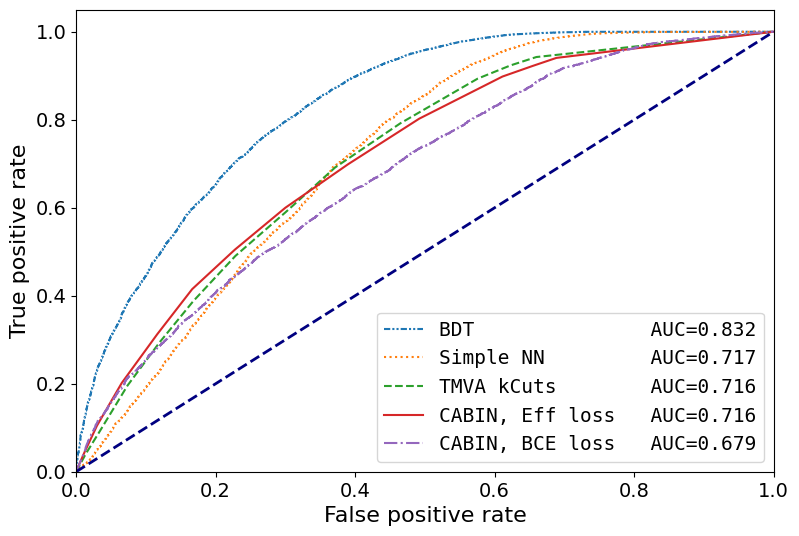

In [142]:
plt.figure(figsize=(9,6))
for method in methods:
    plt.plot(fprs[method],tprs[method], label=f"{labels[method]}"+f"AUC={fixaucs[method]:.3f}",linestyle=linestyles[method])
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
font_prop = FontProperties(family='monospace')
plt.legend(loc="lower right",prop=font_prop)
plt.show()

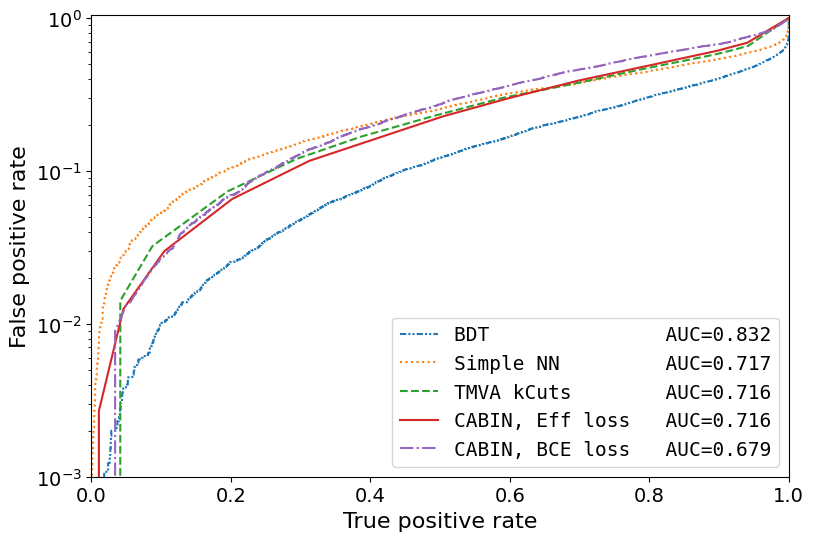

In [141]:
plt.figure(figsize=(9,6))
for method in methods:
    plt.plot(tprs[method],fprs[method], label=f"{labels[method]}"+f"AUC={fixaucs[method]:.3f}",linestyle=linestyles[method])
plt.xlim([0.0, 1.0])
plt.ylim([0.001, 1.05])
plt.ylabel('False positive rate')
plt.xlabel('True positive rate')
plt.yscale('log')
font_prop = FontProperties(family='monospace')
plt.legend(loc="lower right",prop=font_prop)
plt.show()